In [91]:
## Data utilizada: # https://drive.google.com/drive/u/1/folders/1EoxsYIJd2mc5oRf2ZlbAS--bhw5E2MXa  Repertorio A
## Busca en la ambientes el que se llama ig-pipeline
## La primera vez debes reproducir el ambiente en la consola con uv sync (luego de esto ya va a estar disponible siempre)
## Luego solo lo buscas en Python enviroments (aunque se deberia seleccionar solo!)

import matplotlib.pyplot as plt
from seaborn import axes_style
import polars.selectors as cs
import seaborn.objects as so
import seaborn as sns
import polars as pl
import glob
import os



pl.Config.set_tbl_rows(15)

polars.config.Config

In [92]:
# La siguiente función categoriza el espacio clonal en diferentes rangos según el porcentaje de clones presentes en la muestra.

def categorize_clone(clonal_space):
	if(clonal_space<= 0.01):
		return "Small (<=0.01%)"
	elif(clonal_space > 0.01 and clonal_space <= 0.1):
		return "Medium (0.01%-0.1%)"
	elif(clonal_space > 0.1 and clonal_space <= 0.5):
		return "Large (0.1%-0.5%)"
	elif(clonal_space > 0.5 and clonal_space <= 1):
		return "Expanded (0.5%-1%)"
	elif(clonal_space > 1):
		return "Hyperexpanded (>1%)"

# Orden para graficar las categorías
category_order = {
    "Small (<=0.01%)": 1,
    "Medium (0.01%-0.1%)": 2,
    "Large (0.1%-0.5%)": 3,
    "Expanded (0.5%-1%)": 4,
    "Hyperexpanded (>1%)": 5
}

# Colores por categoría 
colormap = {
        "Small (<=0.01%)": "#8bafd9",
        "Medium (0.01%-0.1%)": "#6a88ab",
        "Large (0.1%-0.5%)": "#4a6482",
        "Expanded (0.5%-1%)": "#c45d88",
        "Hyperexpanded (>1%)": "#9e647c",
    }

# Orden en el que se van a mostrar en el eje X
order_samples =[
	"D_100",
	"D_200",
 	"D_400",
 	"D_800",
 	"D_1600",
 	"D_3200",
 	"D_6400",
 	"D_12800",
 	"D_25600",
 	"D_51200",
 	"D_102400"


]

# Modificar en caso de ser necesario
## Cantidad minima de lecturas para considerar un clon como válido
## !!! OJO QUE LOS RESULTADOS CON TUS DATOS CAMBIAN BASTANTE SI ES QUE ES MIN 1 O MIN 2
min_nreads_per_clone = 1
## Flag para indicar si se analizaran todas las lecturas o solo las productivas. 
## En caso de ser True, se analizaran solo las productivas. En caso de ser False, se analizaran todas las lecturas.
filter_by_productive = True

In [93]:
"""
Función para graficar el espacio clonal categorizado por muestra o grupo.
@param df_cat: DataFrame de polars con los datos categorizados. Columnas: 
  - sample, 
  - clon_type: categorias definidas en categorize_clone
  - clonal_space_occupied: porcentaje de ocupancia
  - order: orden de aparición de las barras
  - n_reads_max_cat: cantidad máxima de lecturas por categoría 
@param save: booleano que indica si se desea guardar la figura. Por defecto es False.
@param name: nombre para guardar la figura. Por defecto es "plot".
"""
def plot_categorized_clones(df_cat,show_by,save=False,name="plot"):
    plt.rcParams["figure.dpi"] = 300

    #df_category_summary_gby = df_cat.sort(show_by)
    order_dict = {nombre: i for i, nombre in enumerate(order_samples, start=1)}    
    df_category_summary_gby = df_cat.with_columns(
        order_ = pl.col("sample").replace(order_dict).cast(pl.Int64)
    )

    plot = (
        so.Plot(
            df_category_summary_gby.sort(["order_","order"]),
            x="sample",
            y="clonal_space_occupied",
            color="clon_type",
            #text="n_reads_max_cat"
        )
        .add(so.Bar(alpha=0.8, width=0.8), so.Stack(), legend=True)
        .scale(color=colormap)
        .layout(size=(12, 4), engine="tight")
    ).theme(
        {
            "axes.edgecolor": "#95999d",
            "axes.spines.right": False,
            "axes.spines.top": False,
        }
    )

    #plot = plot.facet(show_by).share(x=False).layout(engine="constrained")
    plot = plot.share(x=False).layout(engine="constrained")

    plot.config.theme.update(axes_style("white"))
    fig = plot.plot()
    if(save==True):
        plot.save(f"{basedir}/figures/{name}.svg", dpi=300, format='svg', bbox_inches='tight')
    return plot

In [94]:
## Input del notebook:
###- Múltiples archivos de clones: uno por cada muestra 
###    - (columnas: sequence_id, sequence, rev_comp, productive, ...., clone_id, etc) 
### Ejemplo: repertorio_A_insilico_30_seqs_clone-pass

basedir = "/Users/catg/Desktop/SOFIAC/Gitsofia/tesisbioinf-sofia/data/downsampling/"

# Buscar exclusivamente archivos D con sufijo clone-pass.tsv
archivos = glob.glob(
    os.path.join(basedir, "repertorio_D_insilico_*_seqs_clone-pass.tsv")
)

In [95]:
## Concatenamos únicamente los archivos clone-pass del escenario
## y añadimos una columna con el nombre del archivo

columnas = ["sequence_id", "clone_id", "productive", "v_call", "v_identity"]

df_raw = pl.concat([
    pl.read_csv(
        file,
        separator="\t",
        columns=columnas,          # solo las columnas que se usan
        infer_schema_length=0,     # lee como texto, sin adivinar tipos
        null_values=["NA"],        # "NA" pasa a ser nulo
    ).with_columns(
        file=pl.lit(os.path.basename(file))
    )
    for file in archivos
])

## Devolver las columnas a su forma original
df_raw = df_raw.with_columns(
    productive=pl.col("productive").replace({"TRUE": "T", "FALSE": "F"}),
    clone_id=pl.col("clone_id").cast(pl.Int64),
    v_identity=pl.col("v_identity").cast(pl.Float64),
).drop_nulls(["clone_id"])

## Extraemos el nombre de la muestra y procesamos las columnas
df_raw = df_raw.with_columns(
    sample=(
        pl.col("file")
        .str.extract(r"repertorio_(.*)_seqs.*", 1)
    ),
    v=pl.col("v_call").str.split("*").list.get(0),
    v_homology=(pl.col("v_identity") * 100).round(2),
).with_columns(
    sample=pl.col("sample").str.replace("insilico_", "")
)

## Comprobamos las muestras cargadas
print(df_raw.select("sample").unique())
print(df_raw.select("productive").unique())   # debe mostrar "T" y "F"
print(df_raw.head())

shape: (11, 1)
┌──────────┐
│ sample   │
│ ---      │
│ str      │
╞══════════╡
│ D_400    │
│ D_800    │
│ D_100    │
│ D_51200  │
│ D_12800  │
│ D_3200   │
│ D_102400 │
│ D_6400   │
│ D_200    │
│ D_25600  │
│ D_1600   │
└──────────┘
shape: (1, 1)
┌────────────┐
│ productive │
│ ---        │
│ str        │
╞════════════╡
│ T          │
└────────────┘
shape: (5, 9)
┌────────────┬────────────┬────────────┬───────────┬───┬───────────┬────────┬──────────┬───────────┐
│ sequence_i ┆ productive ┆ v_call     ┆ v_identit ┆ … ┆ file      ┆ sample ┆ v        ┆ v_homolog │
│ d          ┆ ---        ┆ ---        ┆ y         ┆   ┆ ---       ┆ ---    ┆ ---      ┆ y         │
│ ---        ┆ str        ┆ str        ┆ ---       ┆   ┆ str       ┆ str    ┆ str      ┆ ---       │
│ str        ┆            ┆            ┆ f64       ┆   ┆           ┆        ┆          ┆ f64       │
╞════════════╪════════════╪════════════╪═══════════╪═══╪═══════════╪════════╪══════════╪═══════════╡
│ seq100647  ┆ T         

In [96]:
# cantidad de lecturas por muestra
df_raw.group_by("sample").count().sort("sample")

/var/folders/xn/cc3cddld1_zg1bd74glpn6v00000gp/T/ipykernel_3445/3581952315.py:2: DeprecationWarning: `GroupBy.count` was renamed; use `GroupBy.len` instead
  df_raw.group_by("sample").count().sort("sample")


sample,count
str,u32
"""D_100""",100
"""D_102400""",102391
"""D_12800""",12800
"""D_1600""",1600
"""D_200""",200
"""D_25600""",25600
"""D_3200""",3200
"""D_400""",400
"""D_51200""",51200


In [97]:
# Filtramos solo por lecturas productivas
if(filter_by_productive):
    df_raw_f = df_raw.filter(pl.col("productive") == "T")
else:
    df_raw_f = df_raw

# Eliminamos aquellos clones con  menos de min_nreads_per_clone lecturtas
df_raw_f = (df_raw_f
                .with_columns(nreads_clone = pl.len().over("sample","clone_id"))
                .filter(pl.col("nreads_clone")>=min_nreads_per_clone)
)

df_raw.group_by("sample").count().sort("sample").select("sample").to_dict()


/var/folders/xn/cc3cddld1_zg1bd74glpn6v00000gp/T/ipykernel_3445/1897598872.py:13: DeprecationWarning: `GroupBy.count` was renamed; use `GroupBy.len` instead
  df_raw.group_by("sample").count().sort("sample").select("sample").to_dict()


{'sample': shape: (11,)
 Series: 'sample' [str]
 [
 	"D_100"
 	"D_102400"
 	"D_12800"
 	"D_1600"
 	"D_200"
 	"D_25600"
 	"D_3200"
 	"D_400"
 	"D_51200"
 	"D_6400"
 	"D_800"
 ]}

In [98]:
## Agrupamos por muestra y clon, calculamos el porcentaje de cada clon en la muestra y categorizamos según el porcentaje

df_filter_clone_cat = (df_raw_f
 .group_by("sample","clone_id")
 .agg(pl.len())
 .with_columns(perc = (pl.col("len")/pl.col("len").sum().over(["sample"]) * 100).round(4))
 .sort("perc", descending=True)
 ).with_columns(pl.col("perc").map_elements(categorize_clone).alias("clon_type"))

display(df_filter_clone_cat.head(5))
display(df_filter_clone_cat.group_by("sample","clon_type").agg(pl.len()).sort("len", descending=True).head(5))

sample,clone_id,len,perc,clon_type
str,i64,u32,f64,str
"""D_200""",39488,10,5.0,"""Hyperexpanded (>1%)"""
"""D_800""",40571,33,4.125,"""Hyperexpanded (>1%)"""
"""D_100""",38701,4,4.0,"""Hyperexpanded (>1%)"""
"""D_100""",39488,4,4.0,"""Hyperexpanded (>1%)"""
"""D_400""",39488,15,3.75,"""Hyperexpanded (>1%)"""


sample,clon_type,len
str,str,u32
"""D_102400""","""Small (<=0.01%)""",41459
"""D_51200""","""Small (<=0.01%)""",22214
"""D_25600""","""Small (<=0.01%)""",11573
"""D_12800""","""Small (<=0.01%)""",5940
"""D_6400""","""Medium (0.01%-0.1%)""",3437


In [99]:
# Añadimos el espacio clonal ocupado
df_category_summary = (df_filter_clone_cat
                       .group_by("sample","clon_type","len","perc")
                       .agg(pl.sum("perc").alias("clonal_space_occ"))
                      )
  
df_category_summary_gby = (df_category_summary
                            .group_by("sample","clon_type")
                            .agg(pl.sum("clonal_space_occ")
                            .alias("clonal_space_occupied"))
                          )


df_category_summary_gby = (df_category_summary_gby
                              .with_columns(
                                    order = pl.col("clon_type").replace(category_order)    ,
                              )
                           )




df_category_summary_gby =  df_category_summary_gby.sort("sample")
df_category_summary_gby.head()

sample,clon_type,clonal_space_occupied,order
str,str,f64,str
"""D_100""","""Hyperexpanded (>1%)""",29.0,"""5"""
"""D_100""","""Expanded (0.5%-1%)""",71.0,"""4"""
"""D_102400""","""Small (<=0.01%)""",50.6488,"""1"""
"""D_102400""","""Expanded (0.5%-1%)""",10.1913,"""4"""
"""D_102400""","""Medium (0.01%-0.1%)""",10.7758,"""2"""


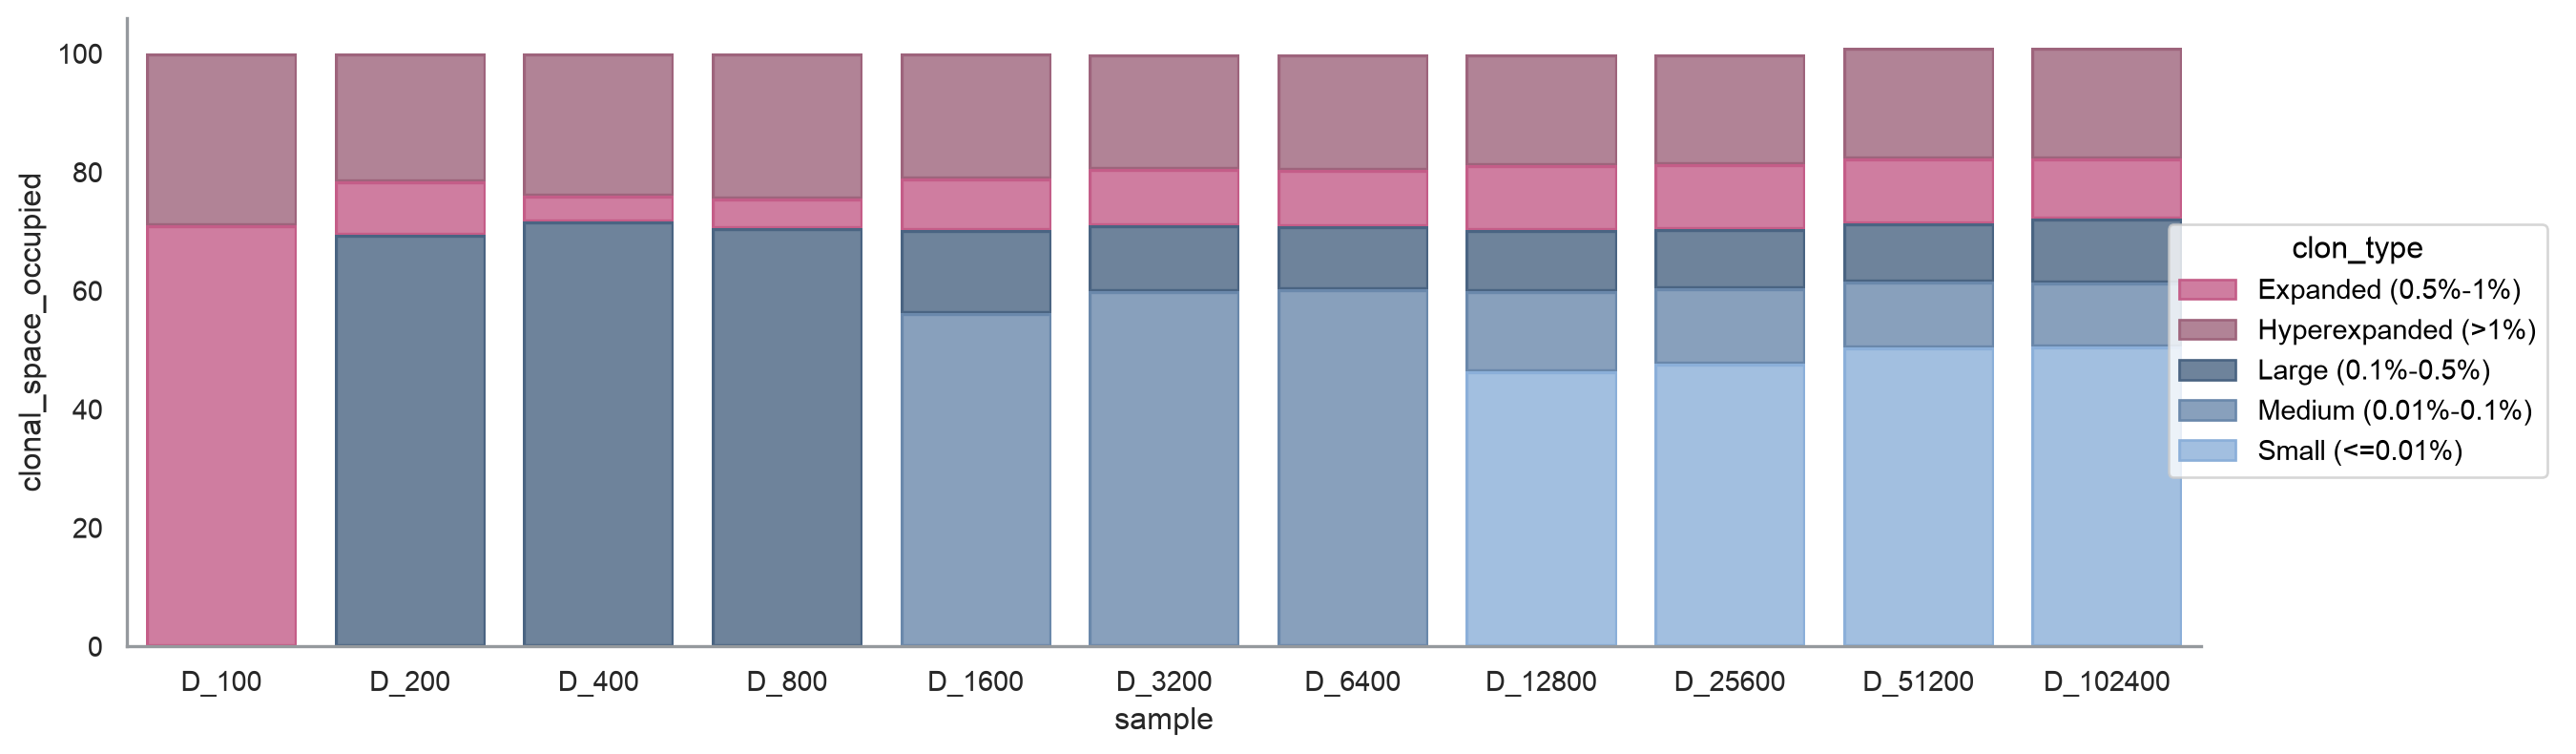

In [100]:
plott = plot_categorized_clones(df_category_summary_gby,"sample", save=False)
plott